# Test 2: Auswertung der temporalen Stabilität

Dieses Notebook untersucht, wie häufig und wie stark sich die geschätzten Lichtparameter nach einem neuen Environment-Probe-Update ändern. Verglichen werden ein Durchgang **mit Stabilisierung** und ein Durchgang **ohne Stabilisierung**.

Wichtige Auswertungsregeln:

- Änderungen werden primär nur zwischen aufeinanderfolgenden Probes mit derselben dominanten `stable_id` verglichen.
- Ein Wechsel der `stable_id` wird separat als Dominanzwechsel ausgewiesen. Er ist keine kleine Parameteränderung derselben Quelle.
- Für jeden Parameter werden Rohwert, geglätteter Kandidat und tatsächliche Ausgabe unterschieden.
- Die Stichprobe ist klein. Die Ergebnisse sind deskriptiv und nicht als inferenzstatistischer Nachweis zu verstehen.

## 1. Konfiguration

Die voreingestellten Ordner verweisen auf die beiden vorhandenen Testläufe. Für weitere Messungen müssen nur die Pfade im folgenden Dictionary geändert oder ergänzt werden.

In [5]:
from pathlib import Path
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

RUN_FOLDERS = {
    "Mit Stabilisierung": Path("data/Test2_with_stabi"),
    "Ohne Stabilisierung": Path("data/Test2_without_stabi"),
}

# Position wird in dieser Auswertung absichtlich nicht verwendet.
PARAMETERS = ["Richtung", "Farbe", "Intensität", "Softness"]

# Numerische Schwellen, ab denen die Auswertung einen Wert als geändert zählt.
# Diese Werte sind NICHT die Minimum-Change-Schwellen der Stabilisierung.
CHANGE_DETECTION_THRESHOLDS = {
    "Richtung": 0.01,       # Grad
    "Farbe": 0.001,         # euklidische RGB-Distanz
    "Intensität": 0.1,      # relative Änderung in Prozent
    "Softness": 0.001,      # absolute Änderung
}

# Minimum-Change-Schwellen aus dem aktuellen Anwendungscode.
# Sie werden gegen den neuen geglätteten Kandidaten und den vorherigen
# Ausgabewert geprüft, nicht gegen zwei aufeinanderfolgende Kandidaten.
STABILIZATION_THRESHOLDS = {
    "Richtung": 3.0,         # Grad
    "Farbe": 0.1,           # euklidische RGB-Distanz
    "Intensität": 20.0,     # relative Änderung in Prozent (Code: 0.2)
    "Softness": 0.15,       # absolute Änderung
}

COLORS = {
    "Mit Stabilisierung": "#6F4BAE",
    "Ohne Stabilisierung": "#D97941",
    "Roh": "#D97941",
    "Geglättet": "#4E79A7",
    "Ausgabe": "#6F4BAE",
}

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## 2. Daten laden und prüfen

In [7]:
def parse_bool_columns(frame: pd.DataFrame) -> pd.DataFrame:
    frame = frame.copy()
    for column in frame.columns:
        values = set(frame[column].dropna().astype(str).str.lower().unique())
        if values and values <= {"true", "false"}:
            frame[column] = frame[column].astype(str).str.lower().map({"true": True, "false": False})
    return frame


def load_run(folder: Path) -> dict:
    required = ["sequence-info.csv", "light-parameters.csv", "change-events.csv", "summary.csv"]
    missing = [name for name in required if not (folder / name).exists()]
    if missing:
        raise FileNotFoundError(f"Fehlende Dateien in {folder}: {', '.join(missing)}")

    sequence = pd.read_csv(folder / "sequence-info.csv")
    lights = pd.read_csv(folder / "light-parameters.csv")
    events = parse_bool_columns(pd.read_csv(folder / "change-events.csv"))
    summary_raw = pd.read_csv(folder / "summary.csv")
    summary = dict(zip(summary_raw["metric"], summary_raw["value"]))

    numeric_light_columns = [
        c for c in lights.columns
        if c not in {"step", "timestamp", "placement_resolved"}
    ]
    for column in numeric_light_columns:
        lights[column] = pd.to_numeric(lights[column], errors="coerce")
    for column in ["index", "elapsed_seconds", "capture_id", "average_luminance", "light_count", "dominant_stable_id"]:
        if column in sequence:
            sequence[column] = pd.to_numeric(sequence[column], errors="coerce")

    return {
        "folder": folder,
        "sequence": sequence,
        "lights": lights,
        "events": events,
        "summary": summary,
    }


runs = {}
for name, folder in RUN_FOLDERS.items():
    if folder.exists():
        runs[name] = load_run(folder)
    else:
        warnings.warn(f"Ordner nicht gefunden und deshalb übersprungen: {folder}")

if not runs:
    raise RuntimeError("Keiner der konfigurierten Testordner wurde gefunden.")

print("Geladene Durchgänge:")
for name, run in runs.items():
    print(f"- {name}: {run['folder']}")

Geladene Durchgänge:
- Mit Stabilisierung: data/Test2_with_stabi
- Ohne Stabilisierung: data/Test2_without_stabi


In [8]:
def data_quality_table(runs: dict) -> pd.DataFrame:
    rows = []
    for name, run in runs.items():
        sequence = run["sequence"]
        fresh = sequence.loc[sequence["status"].eq("ok")].sort_values("elapsed_seconds")
        intervals = fresh["elapsed_seconds"].diff().dropna()
        dominant_ids = fresh["dominant_stable_id"].dropna().astype(int)
        switches = int((dominant_ids.diff().dropna() != 0).sum())
        rows.append({
            "Durchgang": name,
            "Dauer (s)": sequence["elapsed_seconds"].max(),
            "Geplante Zeitpunkte": len(sequence),
            "Frische Probes": len(fresh),
            "Zeitpunkte ohne neue Probe": int(sequence["status"].eq("no_fresh_capture").sum()),
            "Mittlerer Probe-Abstand (s)": intervals.mean(),
            "Maximaler Probe-Abstand (s)": intervals.max(),
            "Dominanzwechsel": switches,
            "Vergleichbare Übergänge": max(len(fresh) - 1 - switches, 0),
        })
    return pd.DataFrame(rows).set_index("Durchgang")


quality = data_quality_table(runs)
display(quality.round(2))

,Dauer (s),Geplante Zeitpunkte,Frische Probes,Zeitpunkte ohne neue Probe,Mittlerer Probe-Abstand (s),Maximaler Probe-Abstand (s),Dominanzwechsel,Vergleichbare Übergänge
Durchgang,,,,,,,,
Mit Stabilisierung,62.580,31,7,24,4.960,11.670,1,5
Ohne Stabilisierung,62.190,31,8,23,6.950,14.380,3,4


**Lesart:** „Frische Probes“ sind tatsächlich neu eingetroffene Environment-Probe-Updates. „Vergleichbare Übergänge“ sind aufeinanderfolgende Updates, bei denen die dominante Stable ID gleich blieb. Nur diese Übergänge eignen sich für die Bewertung kleiner zeitlicher Änderungen.

## 3. Änderungsmetriken berechnen

In [9]:
def vector(row, prefix, components):
    return np.array([row[f"{prefix}{component}"] for component in components], dtype=float)


def direction_angle_degrees(a, b):
    norm_a = np.linalg.norm(a)
    norm_b = np.linalg.norm(b)
    if norm_a < 1e-12 or norm_b < 1e-12:
        return 180.0 if np.linalg.norm(a - b) > 1e-12 else 0.0
    cosine = np.clip(np.dot(a / norm_a, b / norm_b), -1.0, 1.0)
    return float(np.degrees(np.arccos(cosine)))


def relative_change_percent(a, b):
    return float(abs(b - a) / max(abs(a), 1e-4) * 100.0)


def delta_for_parameter(previous, current, stage, parameter):
    prefixes = {
        "Roh": "raw_",
        "Geglättet": "candidate_",
        "Ausgabe": "",
    }
    prefix = prefixes[stage]

    if parameter == "Richtung":
        a = vector(previous, f"{prefix}direction_", "xyz")
        b = vector(current, f"{prefix}direction_", "xyz")
        return direction_angle_degrees(a, b)
    if parameter == "Farbe":
        a = vector(previous, f"{prefix}color_", "rgb")
        b = vector(current, f"{prefix}color_", "rgb")
        return float(np.linalg.norm(b - a))
    if parameter == "Intensität":
        return relative_change_percent(
            float(previous[f"{prefix}intensity"]),
            float(current[f"{prefix}intensity"]),
        )
    if parameter == "Softness":
        return float(abs(
            current[f"{prefix}shadow_softness"]
            - previous[f"{prefix}shadow_softness"]
        ))
    raise ValueError(parameter)


def dominant_transitions(run_name, run):
    dominant = (
        run["lights"]
        .loc[lambda frame: frame["light_slot"].eq(0)]
        .sort_values(["index", "elapsed_seconds"])
        .reset_index(drop=True)
    )
    records = []
    for transition_index, (previous_index, current_index) in enumerate(zip(dominant.index[:-1], dominant.index[1:]), start=1):
        previous = dominant.loc[previous_index]
        current = dominant.loc[current_index]
        same_id = int(previous["stable_id"]) == int(current["stable_id"])
        base = {
            "Durchgang": run_name,
            "Übergang": transition_index,
            "Von": previous["step"],
            "Nach": current["step"],
            "Zeit (s)": current["elapsed_seconds"],
            "Stable ID vorher": int(previous["stable_id"]),
            "Stable ID nachher": int(current["stable_id"]),
            "Gleiche Stable ID": same_id,
        }
        for parameter in PARAMETERS:
            for stage in ["Roh", "Geglättet", "Ausgabe"]:
                base[f"{parameter} – {stage}"] = delta_for_parameter(previous, current, stage, parameter)
        records.append(base)
    return pd.DataFrame(records)


transitions = pd.concat(
    [dominant_transitions(name, run) for name, run in runs.items()],
    ignore_index=True,
)
same_id_transitions = transitions.loc[transitions["Gleiche Stable ID"]].copy()

print(f"Übergänge insgesamt: {len(transitions)}")
print(f"Davon mit gleicher Stable ID: {len(same_id_transitions)}")
print(f"Davon Dominanzwechsel: {(~transitions['Gleiche Stable ID']).sum()}")

Übergänge insgesamt: 13
Davon mit gleicher Stable ID: 9
Davon Dominanzwechsel: 4


### Einheiten

- Richtung: Winkeländerung in Grad
- Farbe: euklidische Distanz im RGB-Raum
- Intensität: relative Änderung in Prozent
- Softness: absolute Änderung des verwendeten Parameters

## 4. Wie oft ändert sich nach einer neuen Probe etwas?

In [10]:
def suppression_table(same_id: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for run_name, group in same_id.groupby("Durchgang", sort=False):
        for parameter in PARAMETERS:
            threshold = CHANGE_DETECTION_THRESHOLDS[parameter]
            raw_changed = group[f"{parameter} – Roh"] > threshold
            output_changed = group[f"{parameter} – Ausgabe"] > threshold
            opportunities = int(raw_changed.sum())
            suppressed = int((raw_changed & ~output_changed).sum())
            rows.append({
                "Durchgang": run_name,
                "Parameter": parameter,
                "Vergleichbare Übergänge": len(group),
                "Roh geändert": opportunities,
                "Ausgabe geändert": int(output_changed.sum()),
                "Unterdrückt": suppressed,
                "Unterdrückungsrate (%)": 100 * suppressed / opportunities if opportunities else np.nan,
                "Ausgabe-Änderungsrate (%)": 100 * output_changed.sum() / len(group) if len(group) else np.nan,
            })
    return pd.DataFrame(rows)


suppression = suppression_table(same_id_transitions)
display(
    suppression.set_index(["Durchgang", "Parameter"])
    .round(2)
)

Vergleichbare Übergänge  Roh geändert  Ausgabe geändert  Unterdrückt  Unterdrückungsrate (%)  Ausgabe-Änderungsrate (%)
Durchgang           Parameter                                                                                                                          
Mit Stabilisierung  Richtung                          5             5                 0            5                 100.000                      0.000
                    Farbe                             5             5                 0            5                 100.000                      0.000
                    Intensität                        5             5                 0            5                 100.000                      0.000
                    Softness                          5             2                 0            2                 100.000                      0.000
Ohne Stabilisierung Richtung                          4             4                 4            0                   0.000                    100.000
                    Farbe                             4             4                 4            0                   0.000                    100.000
                    Intensität                        4             4                 4            0                   0.000                    100.000
                    Softness                          4             0                 0            0                     NaN                      0.000

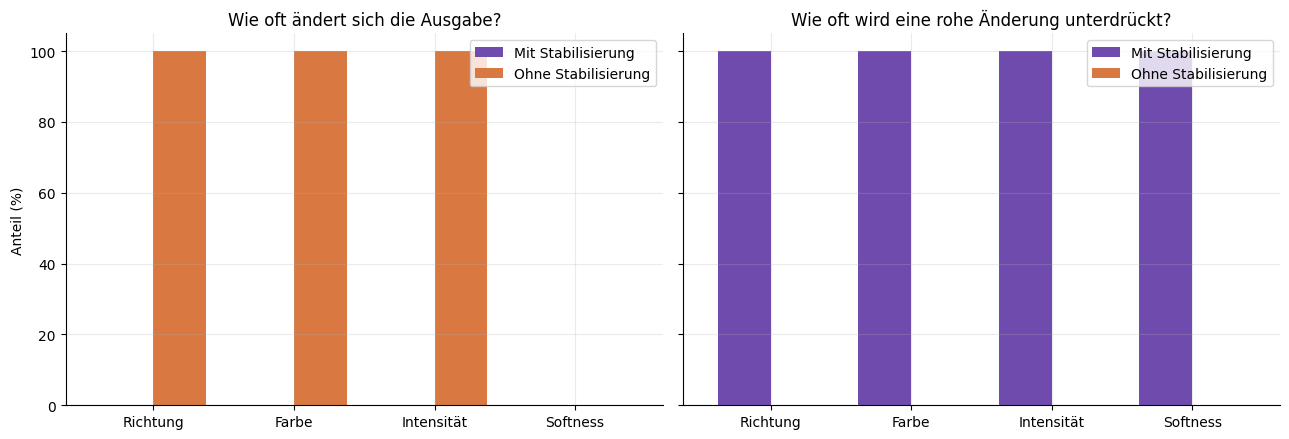

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

for axis, value_column, title in [
    (axes[0], "Ausgabe-Änderungsrate (%)", "Wie oft ändert sich die Ausgabe?"),
    (axes[1], "Unterdrückungsrate (%)", "Wie oft wird eine rohe Änderung unterdrückt?"),
]:
    pivot = suppression.pivot(index="Parameter", columns="Durchgang", values=value_column).reindex(PARAMETERS)
    pivot.plot(
        kind="bar",
        ax=axis,
        color=[COLORS.get(column, "#777777") for column in pivot.columns],
        width=0.75,
    )
    axis.set_title(title)
    axis.set_xlabel("")
    axis.set_ylabel("Anteil (%)")
    axis.set_ylim(0, 105)
    axis.tick_params(axis="x", rotation=0)
    axis.legend(title="")

plt.tight_layout()
plt.show()

## 5. Wie groß sind die Änderungen?

In [12]:
def magnitude_summary(same_id: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for run_name, group in same_id.groupby("Durchgang", sort=False):
        for parameter in PARAMETERS:
            for stage in ["Roh", "Geglättet", "Ausgabe"]:
                values = group[f"{parameter} – {stage}"].dropna()
                rows.append({
                    "Durchgang": run_name,
                    "Parameter": parameter,
                    "Stufe": stage,
                    "n": len(values),
                    "Mittelwert": values.mean(),
                    "Median": values.median(),
                    "Maximum": values.max(),
                })
    return pd.DataFrame(rows)


magnitudes = magnitude_summary(same_id_transitions)
display(
    magnitudes.set_index(["Durchgang", "Parameter", "Stufe"])
    .round(4)
)

n  Mittelwert  Median  Maximum
Durchgang           Parameter  Stufe                                    
Mit Stabilisierung  Richtung   Roh        5       1.491   1.500    3.337
                               Geglättet  5       0.484   0.360    1.085
                               Ausgabe    5       0.000   0.000    0.000
                    Farbe      Roh        5       0.008   0.009    0.011
                               Geglättet  5       0.003   0.003    0.005
                               Ausgabe    5       0.000   0.000    0.000
                    Intensität Roh        5       8.744   5.152   31.422
                               Geglättet  5       2.549   0.951    8.475
                               Ausgabe    5       0.000   0.000    0.000
                    Softness   Roh        5       0.026   0.000    0.108
                               Geglättet  5       0.010   0.000    0.039
                               Ausgabe    5       0.000   0.000    0.000
Ohne Stabilisierung Richtung   Roh        4       1.175   0.673    3.330
                               Geglättet  4       1.175   0.673    3.330
                               Ausgabe    4       1.175   0.673    3.330
                    Farbe      Roh        4       0.005   0.005    0.008
                               Geglättet  4       0.005   0.005    0.008
                               Ausgabe    4       0.005   0.005    0.008
                    Intensität Roh        4      21.264  13.441   57.126
                               Geglättet  4      21.264  13.441   57.126
                               Ausgabe    4      21.264  13.441   57.126
                    Softness   Roh        4       0.000   0.000    0.000
                               Geglättet  4       0.000   0.000    0.000
                               Ausgabe    4       0.000   0.000    0.000

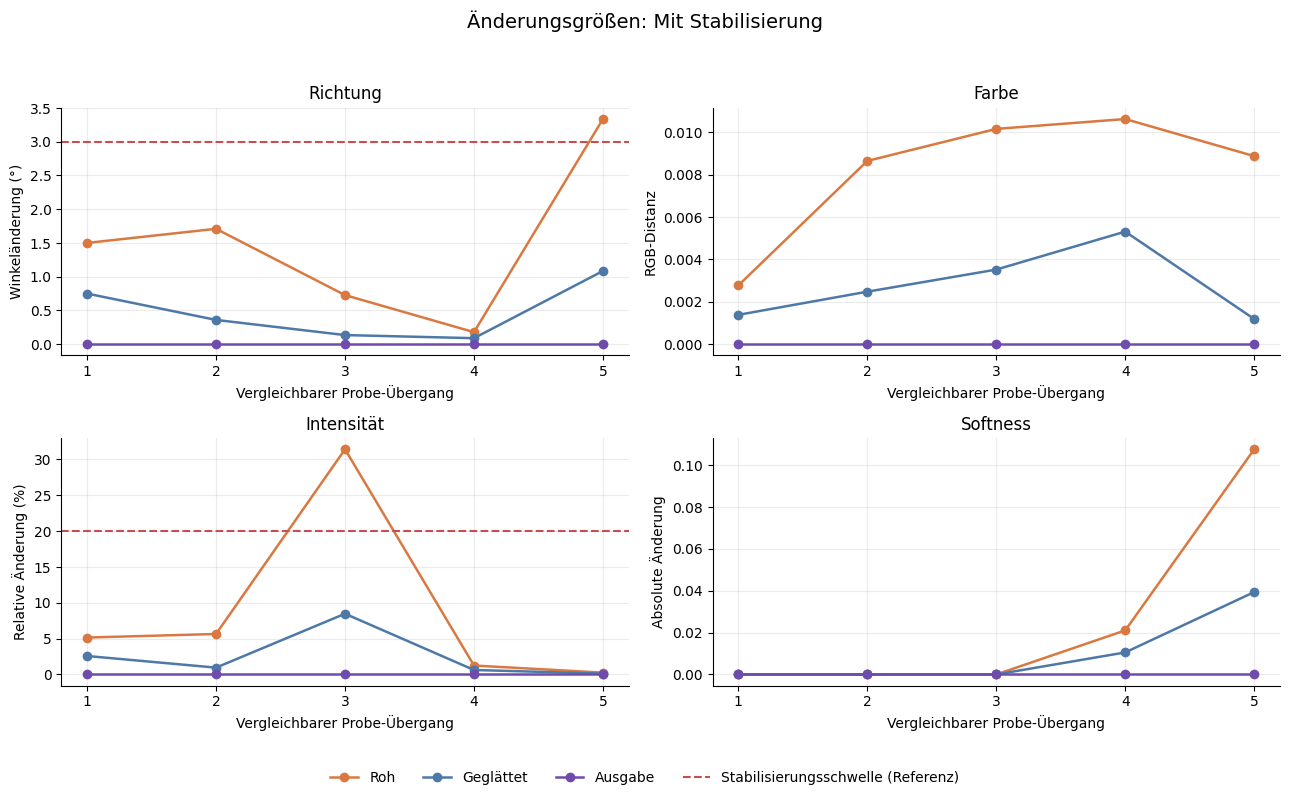

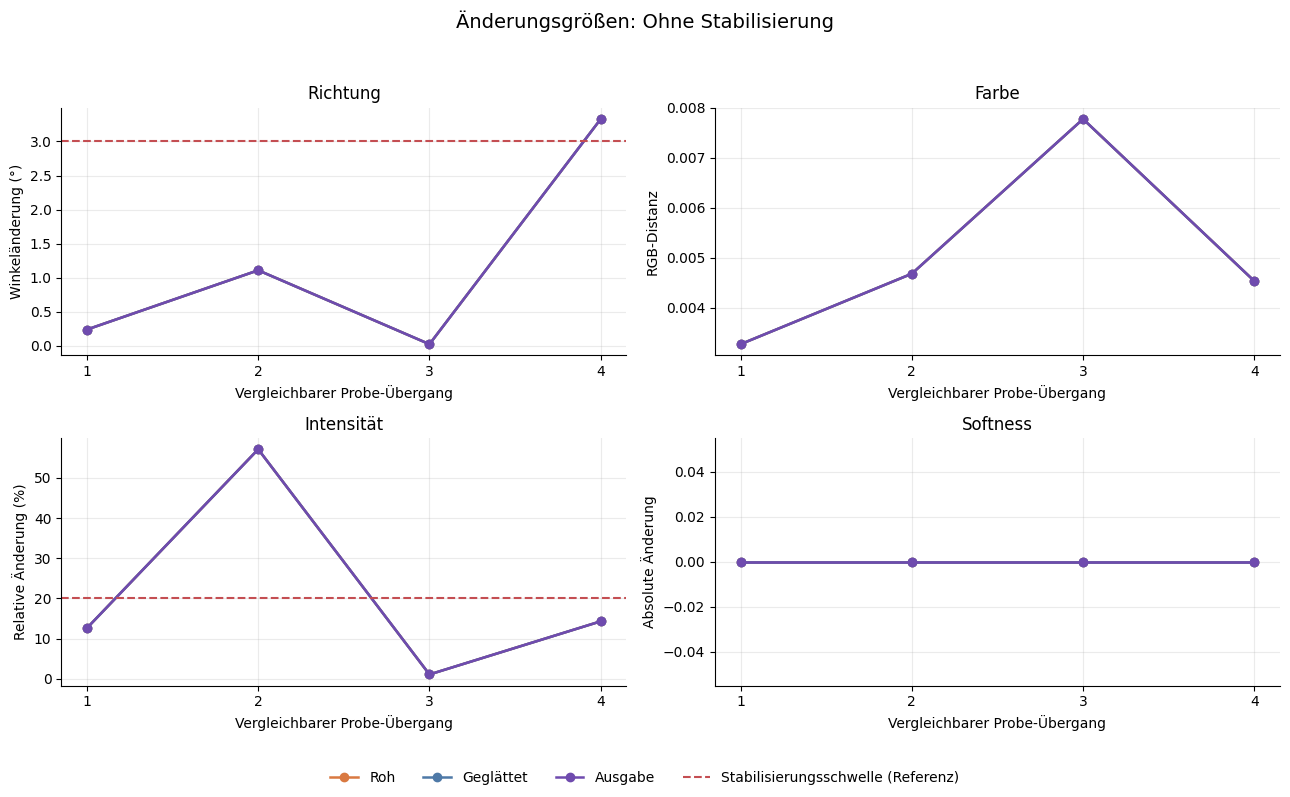

In [13]:
units = {
    "Richtung": "Winkeländerung (°)",
    "Farbe": "RGB-Distanz",
    "Intensität": "Relative Änderung (%)",
    "Softness": "Absolute Änderung",
}

for run_name, group in same_id_transitions.groupby("Durchgang", sort=False):
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    fig.suptitle(f"Änderungsgrößen: {run_name}", fontsize=14)
    for axis, parameter in zip(axes.flat, PARAMETERS):
        x = np.arange(1, len(group) + 1)
        for stage in ["Roh", "Geglättet", "Ausgabe"]:
            axis.plot(
                x,
                group[f"{parameter} – {stage}"],
                marker="o",
                linewidth=1.8,
                label=stage,
                color=COLORS[stage],
            )
        # Den von den Messdaten bestimmten Achsenausschnitt bewahren.
        # Eine außerhalb liegende Schwelle wird dadurch nicht erzwungen sichtbar.
        data_ylim = axis.get_ylim()
        axis.axhline(
            STABILIZATION_THRESHOLDS[parameter],
            color="#C44E52",
            linestyle="--",
            linewidth=1.5,
            label="Stabilisierungsschwelle (Referenz)",
        )
        axis.set_ylim(data_ylim)
        axis.set_title(parameter)
        axis.set_xlabel("Vergleichbarer Probe-Übergang")
        axis.set_ylabel(units[parameter])
        axis.set_xticks(x)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
    fig.tight_layout(rect=(0, 0.06, 1, 0.95))
    plt.show()

Die roten gestrichelten Linien zeigen die Minimum-Change-Schwellen des aktuellen Anwendungscodes als Referenz: 3° für die Richtung, 0,1 für die RGB-Distanz, 20 % für die Intensität und 0,15 für die Softness. Der Achsenausschnitt richtet sich weiterhin ausschließlich nach den Messwerten. Liegt eine Schwelle außerhalb dieses Ausschnitts, wird sie im betreffenden Diagramm nicht sichtbar. Die Kurven vergleichen jeweils zwei aufeinanderfolgende Werte derselben Stufe; die interne Gate-Entscheidung vergleicht dagegen den neuen geglätteten Kandidaten mit dem vorherigen Ausgabewert.

## 6. Detaillierte Übergangstabelle

In [14]:
def detailed_transition_table(group: pd.DataFrame) -> pd.DataFrame:
    columns = ["Von", "Nach", "Stable ID vorher", "Stable ID nachher"]
    for parameter in PARAMETERS:
        columns.extend([
            f"{parameter} – Roh",
            f"{parameter} – Geglättet",
            f"{parameter} – Ausgabe",
        ])
    return group[columns].reset_index(drop=True)


for run_name in runs:
    display(Markdown(f"### {run_name}"))
    group = same_id_transitions.loc[same_id_transitions["Durchgang"].eq(run_name)]
    display(detailed_transition_table(group).round(5))

### Mit Stabilisierung

,Von,Nach,Stable ID vorher,Stable ID nachher,Richtung – Roh,Richtung – Geglättet,Richtung – Ausgabe,Farbe – Roh,Farbe – Geglättet,Farbe – Ausgabe,Intensität – Roh,Intensität – Geglättet,Intensität – Ausgabe,Softness – Roh,Softness – Geglättet,Softness – Ausgabe
0,step-000,step-002,1,1,1.500,0.750,0.000,0.003,0.001,0.000,5.152,2.576,0.000,0.000,0.000,0.000
1,step-002,step-004,1,1,1.710,0.360,0.000,0.009,0.002,0.000,5.647,0.951,0.000,0.000,0.000,0.000
2,step-004,step-005,1,1,0.728,0.135,0.000,0.010,0.004,0.000,31.422,8.475,0.000,0.000,0.000,0.000
3,step-007,step-009,2,2,0.179,0.089,0.000,0.011,0.005,0.000,1.245,0.623,0.000,0.021,0.011,0.000
4,step-009,step-014,2,2,3.337,1.085,0.000,0.009,0.001,0.000,0.255,0.121,0.000,0.108,0.039,0.000


### Ohne Stabilisierung

,Von,Nach,Stable ID vorher,Stable ID nachher,Richtung – Roh,Richtung – Geglättet,Richtung – Ausgabe,Farbe – Roh,Farbe – Geglättet,Farbe – Ausgabe,Intensität – Roh,Intensität – Geglättet,Intensität – Ausgabe,Softness – Roh,Softness – Geglättet,Softness – Ausgabe
0,step-000,step-003,1,1,0.238,0.238,0.238,0.003,0.003,0.003,12.601,12.601,12.601,0.000,0.000,0.000
1,step-003,step-007,1,1,1.108,1.108,1.108,0.005,0.005,0.005,57.126,57.126,57.126,0.000,0.000,0.000
2,step-007,step-010,1,1,0.022,0.022,0.022,0.008,0.008,0.008,1.048,1.048,1.048,0.000,0.000,0.000
3,step-022,step-024,7,7,3.330,3.330,3.330,0.005,0.005,0.005,14.279,14.279,14.279,0.000,0.000,0.000


Diese Tabelle beantwortet für jeden vergleichbaren Probe-Übergang drei Fragen:

1. Wie groß war der rohe Sprung?
2. Wie groß war der Sprung nach der gleitenden Mittelung?
3. Welche Änderung wurde tatsächlich an die Lichtquelle weitergegeben?

Ein Rohwert größer null bei einer Ausgabe von null zeigt eine vollständig unterdrückte Änderung. Eine kleinere, aber nicht null gesetzte Ausgabe zeigt eine geglättete und anschließend übernommene Änderung.

## 7. Stable IDs und Dominanzwechsel

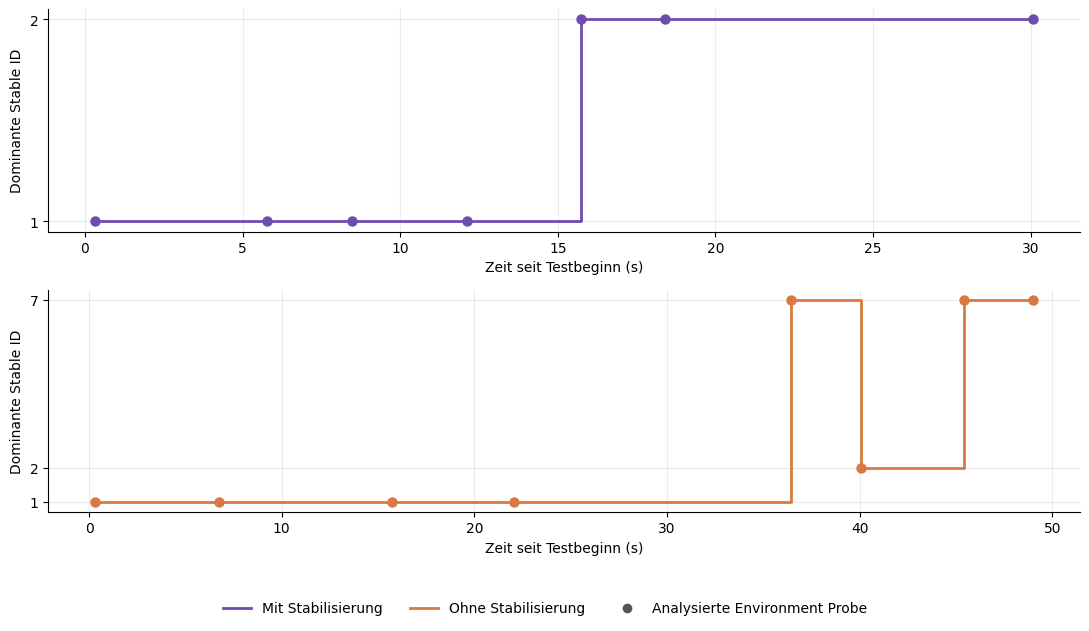

In [15]:
from matplotlib.lines import Line2D

fig, axes = plt.subplots(
    len(runs),
    1,
    figsize=(11, 3.2 * len(runs)),
    squeeze=False,
)

for axis, (run_name, run) in zip(axes.flat, runs.items()):
    dominant = (
        run["lights"]
        .loc[lambda frame: frame["light_slot"].eq(0)]
        .sort_values("elapsed_seconds")
    )
    color = COLORS.get(run_name, "#777777")

    axis.step(
        dominant["elapsed_seconds"],
        dominant["stable_id"],
        where="post",
        color=color,
        linewidth=2,
    )
    axis.scatter(
        dominant["elapsed_seconds"],
        dominant["stable_id"],
        color=color,
        s=42,
        zorder=3,
    )
    axis.set_xlabel("Zeit seit Testbeginn (s)")
    axis.set_ylabel("Dominante Stable ID")
    axis.set_yticks(sorted(dominant["stable_id"].dropna().astype(int).unique()))

legend_elements = [
    Line2D([0], [0], color=COLORS["Mit Stabilisierung"], linewidth=2, label="Mit Stabilisierung"),
    Line2D([0], [0], color=COLORS["Ohne Stabilisierung"], linewidth=2, label="Ohne Stabilisierung"),
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor="#555555",
        markeredgecolor="#555555",
        markersize=6,
        label="Analysierte Environment Probe",
    ),
]
fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, 0.01),
)

fig.tight_layout(rect=(0, 0.10, 1, 1))
plt.show()

In [16]:
switch_rows = transitions.loc[~transitions["Gleiche Stable ID"], [
    "Durchgang", "Von", "Nach", "Zeit (s)", "Stable ID vorher", "Stable ID nachher"
]]

if len(switch_rows):
    display(switch_rows.reset_index(drop=True).round(3))
else:
    print("Keine Dominanzwechsel vorhanden.")

,Durchgang,Von,Nach,Zeit (s),Stable ID vorher,Stable ID nachher
0,Mit Stabilisierung,step-005,step-007,15.741,1,2
1,Ohne Stabilisierung,step-010,step-017,36.418,1,7
2,Ohne Stabilisierung,step-017,step-019,40.043,7,2
3,Ohne Stabilisierung,step-019,step-022,45.408,2,7


## 8. Updatefrequenz und Luminanz der Environment Probes

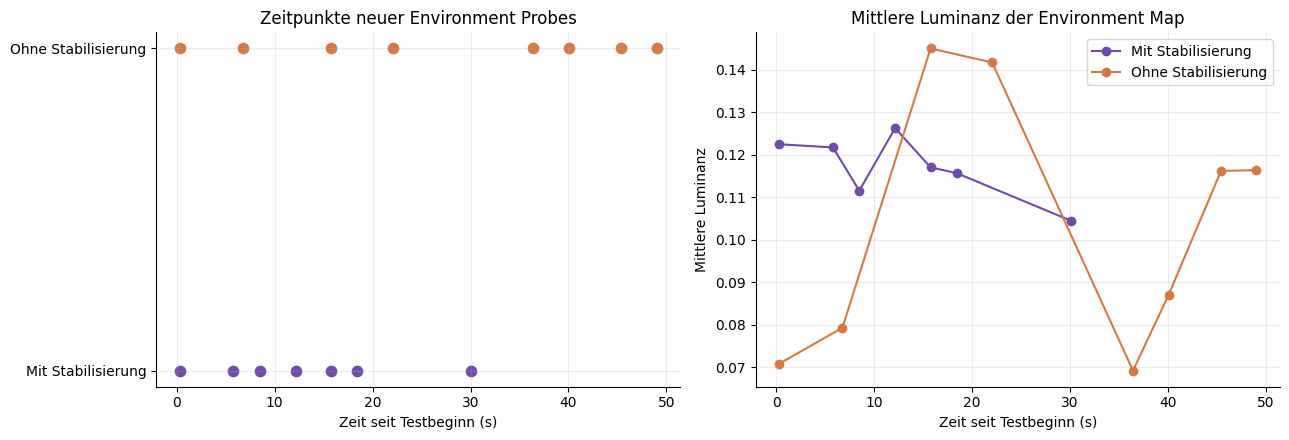

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for run_name, run in runs.items():
    sequence = run["sequence"]
    fresh = sequence.loc[sequence["status"].eq("ok")].sort_values("elapsed_seconds")
    axes[0].scatter(
        fresh["elapsed_seconds"],
        [run_name] * len(fresh),
        s=55,
        color=COLORS.get(run_name, "#777777"),
        label=run_name,
    )
    axes[1].plot(
        fresh["elapsed_seconds"],
        fresh["average_luminance"],
        marker="o",
        color=COLORS.get(run_name, "#777777"),
        label=run_name,
    )

axes[0].set_title("Zeitpunkte neuer Environment Probes")
axes[0].set_xlabel("Zeit seit Testbeginn (s)")
axes[0].set_ylabel("")
axes[1].set_title("Mittlere Luminanz der Environment Map")
axes[1].set_xlabel("Zeit seit Testbeginn (s)")
axes[1].set_ylabel("Mittlere Luminanz")
axes[1].legend(title="")

plt.tight_layout()
plt.show()

In [18]:
luminance_rows = []
for run_name, run in runs.items():
    values = run["sequence"].loc[run["sequence"]["status"].eq("ok"), "average_luminance"].dropna()
    luminance_rows.append({
        "Durchgang": run_name,
        "Minimum": values.min(),
        "Maximum": values.max(),
        "Mittelwert": values.mean(),
        "Relative Spannweite (%)": 100 * (values.max() - values.min()) / values.mean() if len(values) else np.nan,
    })

display(pd.DataFrame(luminance_rows).set_index("Durchgang").round(4))

,Minimum,Maximum,Mittelwert,Relative Spannweite (%)
Durchgang,,,,
Mit Stabilisierung,0.104,0.126,0.117,18.631
Ohne Stabilisierung,0.069,0.145,0.103,73.479


## 9. Kompakter Vergleich der beiden Durchgänge

In [19]:
comparison_rows = []
for run_name, group in same_id_transitions.groupby("Durchgang", sort=False):
    row = {
        "Durchgang": run_name,
        "Vergleichbare Übergänge": len(group),
        "Dominanzwechsel": int((~transitions.loc[transitions["Durchgang"].eq(run_name), "Gleiche Stable ID"]).sum()),
    }
    any_raw = np.zeros(len(group), dtype=bool)
    any_output = np.zeros(len(group), dtype=bool)
    for parameter in PARAMETERS:
        threshold = CHANGE_DETECTION_THRESHOLDS[parameter]
        any_raw |= group[f"{parameter} – Roh"].to_numpy() > threshold
        any_output |= group[f"{parameter} – Ausgabe"].to_numpy() > threshold
        row[f"{parameter}: Ausgabe geändert (%)"] = 100 * (
            group[f"{parameter} – Ausgabe"] > threshold
        ).mean() if len(group) else np.nan
    row["Mindestens ein Rohparameter geändert (%)"] = 100 * any_raw.mean() if len(group) else np.nan
    row["Mindestens ein Ausgabeparameter geändert (%)"] = 100 * any_output.mean() if len(group) else np.nan
    comparison_rows.append(row)

comparison = pd.DataFrame(comparison_rows).set_index("Durchgang")
display(comparison.round(1))

,Vergleichbare Übergänge,Dominanzwechsel,Richtung: Ausgabe geändert (%),Farbe: Ausgabe geändert (%),Intensität: Ausgabe geändert (%),Softness: Ausgabe geändert (%),Mindestens ein Rohparameter geändert (%),Mindestens ein Ausgabeparameter geändert (%)
Durchgang,,,,,,,,
Mit Stabilisierung,5,1,0.000,0.000,0.000,0.000,100.000,0.000
Ohne Stabilisierung,4,3,100.000,100.000,100.000,0.000,100.000,100.000


In [15]:
display(Markdown("### Automatisch erzeugte Kurzinterpretation"))

for run_name in comparison.index:
    comparable = int(comparison.loc[run_name, "Vergleichbare Übergänge"])
    switches = int(comparison.loc[run_name, "Dominanzwechsel"])
    any_output_rate = comparison.loc[run_name, "Mindestens ein Ausgabeparameter geändert (%)"]
    fresh_count = int(quality.loc[run_name, "Frische Probes"])
    print(
        f"{run_name}: {fresh_count} frische Probes, {comparable} vergleichbare Übergänge, "
        f"{switches} Dominanzwechsel. Bei {any_output_rate:.1f} % der vergleichbaren Übergänge "
        "änderte sich mindestens ein ausgegebener Erscheinungsparameter."
    )

print("\nFür den Ergebnistext sollten Anzahl der Probes, vergleichbare Übergänge und Dominanzwechsel immer mit angegeben werden.")

### Automatisch erzeugte Kurzinterpretation

Mit Stabilisierung: 7 frische Probes, 5 vergleichbare Übergänge, 1 Dominanzwechsel. Bei 0.0 % der vergleichbaren Übergänge änderte sich mindestens ein ausgegebener Erscheinungsparameter.
Ohne Stabilisierung: 8 frische Probes, 4 vergleichbare Übergänge, 3 Dominanzwechsel. Bei 100.0 % der vergleichbaren Übergänge änderte sich mindestens ein ausgegebener Erscheinungsparameter.

Für den Ergebnistext sollten Anzahl der Probes, vergleichbare Übergänge und Dominanzwechsel immer mit angegeben werden.
